In [1]:
import sys

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
from mujoco import mjx


In [2]:
# 1. Load your hexapod scene using standard MuJoCo
file = "../models/SELF_Hexapod/scene.xml"
mj_model = mujoco.MjModel.from_xml_path(file) #type: ignore
spec = mujoco.MjSpec.from_file(file) #type: ignore
mj_data = mujoco.MjData(mj_model) #type: ignore

# 2. Transfer the model and data structures to MJX (JAX/GPU arrays)
# This converts rigid bodies, tendons, and constraints into XLA graphs
model = mjx.put_model(mj_model)
data = mjx.put_data(mj_model, mj_data)
renderer = mujoco.Renderer(mj_model)

""

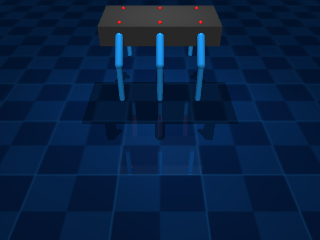

In [3]:
# viz scene and model
mujoco.mj_forward(mj_model, mj_data) #type: ignore
renderer.update_scene(mj_data, camera="fixed_cam")
media.show_image(renderer.render())

In [4]:
# 3. Create a differentiable step function using XLA JIT Compilation
@jax.jit
def differentiable_simulation_step(current_state, actions):
    """
    Takes the current MJX data state and an action vector, 
    steps the physics engine natively on the GPU, and returns the next state.
    """
    # Inject actions into the tendon actuators
    state_with_action = current_state.replace(ctrl=actions)
    
    # Step the solver forward (completely differentiable!)
    next_state = mjx.step(model, state_with_action)
    return next_state

# 4. Example: Compute analytical gradients of the torso height with respect to tendon actions
def calculate_loss(actions, initial_state):
    # Predict the next physics frame
    predicted_state = differentiable_simulation_step(initial_state, actions)
    
    # Target: We want the torso height (qpos[2]) to stay at exactly 0.4 meters
    torso_height = predicted_state.qpos[2]
    loss = jnp.square(torso_height - 0.4)
    return loss



In [5]:
# Reverse-mode autodiff straight through the physics.
#
# MJX only differentiates its constraint solver when opt.iterations == 1 — see
# mjx/_src/solver.py, which otherwise wraps the solve in a lax.while_loop, and
# while_loop has no reverse-mode rule. hexapod.xml sets iterations="1" for that
# reason; on this scene it costs nothing (identical settled height and contact
# penetration as iterations=100, since one Newton step already converges).
grad_loss_fn = jax.grad(calculate_loss)

# Take the gradient at a *loaded* pose: standing, with the knees pushing.
# At ctrl=0 the robot sits in equilibrium with its feet stuck to the floor, and
# every gradient is ~0 — true, but a useless demo.
settled = mujoco.MjData(mj_model)
for _ in range(500):
    mujoco.mj_step(mj_model, settled)
settled_state = mjx.put_data(mj_model, settled)

test_actions = jnp.array([0.0, 0.3] * 6)  # (hip, knee) per leg
analytical_gradients = grad_loss_fn(test_actions, settled_state)

print(f"torso height {settled.qpos[2]:.3f} m, {settled.ncon} feet on the floor\n")
for i, g in enumerate(analytical_gradients):
    name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_ACTUATOR, i)
    print(f"  d(height loss)/d({name:13s}) = {g:+.3e}")

# Hips rotate about z (they swing the leg sideways) so they cannot change torso
# height; knees rotate about x and extend the leg, so they carry all the signal.


torso height 0.215 m, 6 feet on the floor

  d(height loss)/d(act_hip_fl   ) = -2.289e-09
  d(height loss)/d(act_knee_fl  ) = -1.664e-05
  d(height loss)/d(act_hip_ml   ) = -2.720e-09
  d(height loss)/d(act_knee_ml  ) = -1.671e-05
  d(height loss)/d(act_hip_bl   ) = +1.462e-08
  d(height loss)/d(act_knee_bl  ) = -1.664e-05
  d(height loss)/d(act_hip_fr   ) = -3.299e-10
  d(height loss)/d(act_knee_fr  ) = -1.663e-05
  d(height loss)/d(act_hip_mr   ) = -4.886e-09
  d(height loss)/d(act_knee_mr  ) = +4.305e-06
  d(height loss)/d(act_hip_br   ) = -9.468e-09
  d(height loss)/d(act_knee_br  ) = -1.663e-05


In [6]:
DURATION = 3
FRAMERATE = 60

# Reset the standard state, then transfer the reset state to MJX.
# NOTE: the model defines no keyframes, so the previous mj_resetDataKeyframe(..., 1)
# silently did nothing. mj_resetData puts us at the default pose (torso at z=0.4).
mujoco.mj_resetData(mj_model, mj_data)
mjx_data = mjx.put_data(mj_model, mj_data)

frames = []
action = jnp.asarray(test_actions)

while float(mjx_data.time) < DURATION:
    # Advance the MJX simulation using the specified tendon actions.
    mjx_data = differentiable_simulation_step(mjx_data, action)

    # Copy the MJX state to standard MuJoCo for rendering.
    mj_data.qpos[:] = jax.device_get(mjx_data.qpos)
    mj_data.qvel[:] = jax.device_get(mjx_data.qvel)
    mj_data.time = float(mjx_data.time)

    mujoco.mj_forward(mj_model, mj_data)

    if len(frames) < mj_data.time * FRAMERATE:
        # tracking_cam follows the torso, so the robot stays framed as it moves
        renderer.update_scene(mj_data, camera="tracking_cam")
        frames.append(renderer.render())

media.show_video(frames, fps=FRAMERATE)


This browser does not support the video tag.


## The brain

A randomly-initialized MLP wired to the 12 position servos. It is untrained, so
expect flailing — the point is that the loop is closed: the body's state reaches
the network and the network's output reaches the actuators.

In [7]:
import brain  # installed by `uv sync`, no sys.path juggling needed

limits = brain.joint_limits(mj_model)
params = brain.mlp.init(
    jax.random.key(0), [brain.obs_dim(mj_model), 64, 64, mj_model.nu]
)

print("observation:", brain.obs_dim(mj_model), "-> actuators:", mj_model.nu)


@jax.jit
def brain_step(state):
    """Close the loop: state -> observation -> MLP -> joint targets -> physics."""
    ctrl = brain.act(params, state, limits)
    return mjx.step(model, state.replace(ctrl=ctrl)), ctrl


observation: 37 -> actuators: 12


This browser does not support the video tag.


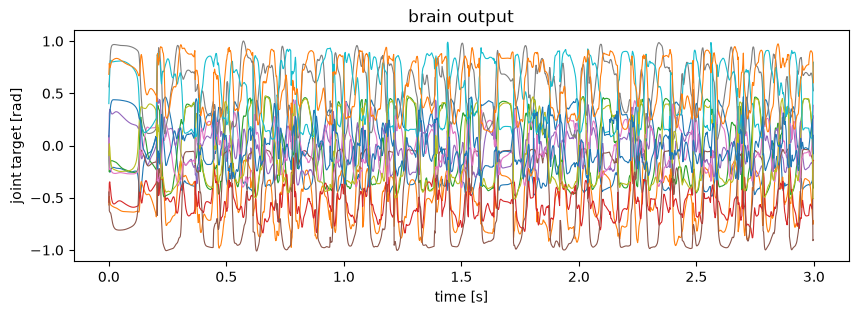

In [8]:

mujoco.mj_resetData(mj_model, mj_data)
mjx_data = mjx.put_data(mj_model, mj_data)

frames, ctrl_log = [], []

while float(mjx_data.time) < DURATION:
    mjx_data, ctrl = brain_step(mjx_data)
    ctrl_log.append(jax.device_get(ctrl))

    mj_data.qpos[:] = jax.device_get(mjx_data.qpos)
    mj_data.qvel[:] = jax.device_get(mjx_data.qvel)
    mj_data.time = float(mjx_data.time)
    mujoco.mj_forward(mj_model, mj_data)

    if len(frames) < mj_data.time * FRAMERATE:
        renderer.update_scene(mj_data, camera="tracking_cam")
        frames.append(renderer.render())

media.show_video(frames, fps=FRAMERATE)

# What the brain actually commanded, one line per joint.
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(ctrl_log)) * mj_model.opt.timestep, np.array(ctrl_log), lw=0.8)
plt.xlabel("time [s]")
plt.ylabel("joint target [rad]")
plt.title("brain output")
plt.show()
